# Does anomaly detection with path signatures add information?

**The question.** Aayush's detector (distance of a window's signature from a "calm" average) flags windows that are followed by high volatility, but so do GARCH and a plain volatility z-score. That test rewards volatility clustering. Here we ask whether signature-based anomaly scores tell us something *beyond* what a volatility model already knows.

**How a detector is built.**
- Each row scores the latest window (1 hour: 1 day of 5-minute bars; 1 day: 7 days of hourly bars).
- The window becomes a path: cumulative return, volume share, range and signed flow. Optionally, the path is divided by the volatility measured *before* the window, so the detector sees shape, not level.
- The path is summarised four ways: **signature** (depth 2–4), a **lag bank** with the same number of columns, hand-built **stats**, and **raw** block sums.
- **Mahalanobis** (expected-signature distance), **Isolation Forest** and an **autoencoder** learn "normal" from the training rows and score each new window.

**How a detector is judged.**
- A *missed event* is one of the 20% of rows where realized volatility most exceeded the HAR-RV forecast.
- The main number is the AUC of the score for predicting missed events, computed within calm, medium and volatile buckets (*stratified*). 0.5 means no information beyond HAR.
- Configs are chosen on the first folds and confirmed on the last one, with purged walk-forward folds throughout.

**The gate.** Signatures count as useful only if the best signature setup beats the best signature-free setup, including the vol baselines, on the selection folds **and** on the last fold (block bootstrap, p < 0.05). If not, we stop and report the negative result.

In [1]:
import sys, importlib, logging
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path.cwd().parent))  # repo root, so `anomaly` and Mihika/ import
import anomaly
from anomaly import config as C, features, detectors, evaluate, run as RUN, report as R
for _m in (C, features, detectors, evaluate, RUN, R):
    importlib.reload(_m)

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(message)s", datefmt="%H:%M:%S")
pd.set_option("display.float_format", "{:.3f}".format)

## 1. Configuration

In [2]:
QUICK = False  # True: small grid on 2023+ data to check that everything runs

cfg = C.AnomalyConfig(
    horizons=("1h", "1d"),
    start="2017-08-01",                  # Binance 1-minute klines, cached under data/klines
    target_rows={"1h": 20000, "1d": None},
    output_dir="results/anomaly",
    data_dir="data",
)
if QUICK:
    cfg = cfg.quick()
print(len(cfg.rep_configs()), "path recipes per horizon")
cfg

36 path recipes per horizon


AnomalyConfig(horizons=('1h', '1d'), n_folds=3, min_train_rows=200, start='2017-08-01', end=None, symbol='BTCUSDT', target_rows={'1h': 20000, '1d': None}, channel_sets=('price', 'price+volume', 'price+volume+range+flow'), normalizations=('none', 'trailing_vol'), window_mults=(0.5, 1.0, 2.0), lead_lag=(True, False), depths=(2, 3, 4), max_sig_features=3000, stage_a_detectors=('mahalanobis', 'iforest'), stage_b_top_k=5, ae_epochs=60, ae_patience=8, surprise_quantile=0.8, flag_rate=0.05, n_bootstrap=500, seed=0, data_dir='data', output_dir='results/anomaly', resume=True)

## 2. Run

Each horizon runs in its own process. Finished path recipes are saved, so an interrupted run resumes where it stopped (delete `results/anomaly/<horizon>/` to redo one).

In [3]:
root = RUN.run_all(cfg, subprocess_per_horizon=True)
res = R.load_results(root)
pd.DataFrame(res.meta).T

15:57:33 | Klines BTCUSDT 2017-08 (monthly)
15:57:35 | Klines BTCUSDT 2017-09 (monthly)
15:57:36 | Klines BTCUSDT 2017-10 (monthly)
15:57:37 | Klines BTCUSDT 2017-11 (monthly)
15:57:39 | Klines BTCUSDT 2017-12 (monthly)
15:57:41 | Klines BTCUSDT 2018-01 (monthly)
15:57:42 | Klines BTCUSDT 2018-02 (monthly)
15:57:44 | Klines BTCUSDT 2018-03 (monthly)
15:57:46 | Klines BTCUSDT 2018-04 (monthly)
15:57:48 | Klines BTCUSDT 2018-05 (monthly)
15:57:49 | Klines BTCUSDT 2018-06 (monthly)
15:57:51 | Klines BTCUSDT 2018-07 (monthly)
15:57:53 | Klines BTCUSDT 2018-08 (monthly)
15:57:54 | Klines BTCUSDT 2018-09 (monthly)
15:57:56 | Klines BTCUSDT 2018-10 (monthly)
15:57:58 | Klines BTCUSDT 2018-11 (monthly)
15:57:59 | Klines BTCUSDT 2018-12 (monthly)
15:58:01 | Klines BTCUSDT 2019-01 (monthly)
15:58:03 | Klines BTCUSDT 2019-02 (monthly)
15:58:05 | Klines BTCUSDT 2019-03 (monthly)
15:58:06 | Klines BTCUSDT 2019-04 (monthly)
15:58:08 | Klines BTCUSDT 2019-05 (monthly)
15:58:10 | Klines BTCUSDT 2019-0

,horizon,rows,folds,first_time,last_time,seconds
1h,1h,16094,"[[4023, 4024], [8047, 4023], [12070, 4024]]",2017-08-24 04:00:00+00:00,2026-10-28 21:00:00+00:00,1277.900
1d,1d,3329,"[[831, 832], [1663, 832], [2495, 833]]",2017-09-16 04:00:00+00:00,2026-10-27 04:00:00+00:00,772.600


## 3. The gate: do signatures beat everything signature-free?

`Sig/Free select` are stratified surprise AUCs on the selection folds, and `confirm` the same on the last fold. `Last-fold diff` is signature minus signature-free, with a block-bootstrap 95% CI and a one-sided p-value.

In [4]:
display(R.gate_table(res).style.format(precision=3))

,Horizon,Best signature,Sig select,Sig confirm,Best signature-free,Free select,Free confirm,Last-fold diff,CI low,CI high,p (sig no better),Gate passed
0,1h,signature d4 | price|none|w1|leadlag [mahalanobis],0.556,0.545,lag bank | price|none|w1|time [iforest],0.547,0.526,0.019,-0.005,0.045,0.062,False
1,1d,signature d3 | price|none|w1|time [mahalanobis],0.648,0.582,stats | trailing_vol|w1 [iforest],0.555,0.539,0.043,-0.005,0.104,0.042,True


## 4. Leaderboard

Top configs per horizon by stratified surprise AUC on the selection folds. `AUC_level` and `Fwd_vol_ratio` are Aayush-style metrics (they reward volatility clustering), shown for comparison.

In [5]:
display(R.leaderboard(res, top=12).style.format(precision=3))

,Horizon,Config,Kind,Detector,Select (folds 1-2),Confirm (last fold),AUC_surprise,Lift,AUC_level,Fwd_vol_ratio,n_features
0,1d,signature d3 | price|none|w1|time,signature,mahalanobis,0.648,0.582,0.575,3.406,0.754,3.281,14
1,1d,signature d3 | price|none|w1|leadlag,signature,mahalanobis,0.644,0.585,0.574,2.934,0.762,3.506,39
2,1d,signature d4 | price|none|w1|time,signature,iforest,0.644,0.560,0.573,3.296,0.747,2.966,30
3,1d,signature d3 | price|none|w1|time,signature,iforest,0.643,0.568,0.578,3.368,0.737,2.954,14
4,1d,signature d2 | price|none|w1|leadlag,signature,iforest,0.643,0.564,0.582,3.220,0.733,2.819,12
5,1d,signature d2 | price|none|w1|time,signature,iforest,0.641,0.568,0.581,2.621,0.722,2.575,6
6,1d,signature d3 | price|trailing_vol|w1|time,signature,iforest,0.641,0.578,0.607,2.150,0.641,1.753,14
7,1d,signature d2 | price|trailing_vol|w1|time,signature,iforest,0.639,0.571,0.605,2.029,0.633,1.664,6
8,1d,signature d3 | price|none|w1|leadlag,signature,iforest,0.638,0.564,0.573,3.270,0.749,2.930,39
9,1d,signature d3 | price|trailing_vol|w1|leadlag,signature,mahalanobis,0.638,0.593,0.605,1.895,0.658,1.672,39


## 5. Which representation and detector work?

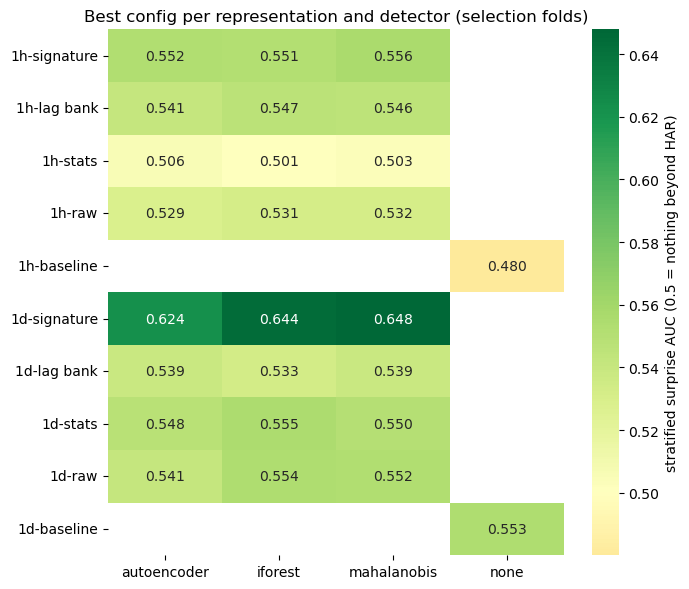

In [6]:
R.plot_kind_heatmap(res); plt.show()

## 6. Synthetic check: shape-only anomalies

For test windows, the same returns are re-ordered into a V or an inverted V. Volatility, net move, skew and kurtosis are unchanged; only the path's shape differs. This shows what each selected detector *can* see in principle. It is not evidence about real markets.

In [7]:
display(R.synthetic_table(res).style.format(precision=3))

,Horizon,Which,Config,Detector,AUC_injected
0,1h,best signature,signature d4 | price|none|w1|leadlag,mahalanobis,0.999
1,1h,best signature-free,lag bank | price|none|w1|time,iforest,0.892
2,1d,best signature,signature d3 | price|none|w1|time,mahalanobis,1.000
3,1d,best signature-free,stats | trailing_vol|w1,iforest,0.596


## 7. Scores over time

Score percentiles of the selected detectors, with the labeled crises shaded (a case study only).

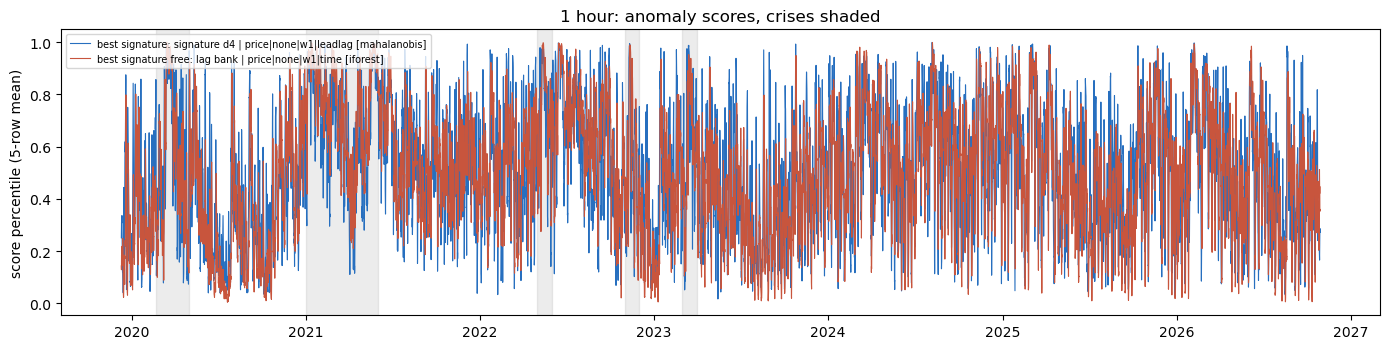

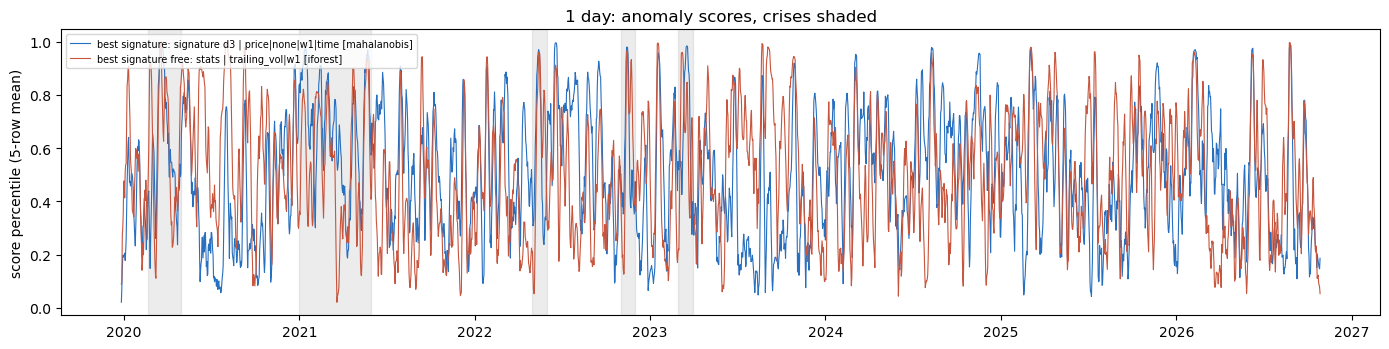

In [8]:
for hk in res.meta:
    R.plot_timeline(res, hk); plt.show()

## 8. What next

- **Gate passed on a horizon:** Phase 2 extends to 5m and 7d, adds the HMM, and uses the selected signature detector in the volatility forecasts as a feature, a residual correction and a regime gate, compared against the best signature-free detector.
- **Gate failed:** the honest result is that signature anomaly scores carry no information beyond volatility clustering at these horizons. Only the single residual-correction test is run in the volatility forecasts.